# LAB1 – Bài 2: Yêu cầu lập trình
**Sinh viên:** Đinh Văn Bình – **MSSV:** 6351071007

## Câu 5: Thống kê số người đi cùng (anh chị em/vợ chồng hoặc cha mẹ/con cái) và khảo sát sự liên quan với thuộc tính quyết định (survived)

In [1]:
print('Họ tên: Đinh Văn Bình - MSSV: 6351071007')

Họ tên: Đinh Văn Bình - MSSV: 6351071007


### Bước 1. Import thư viện và đọc dữ liệu

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt

with open('titanic.csv') as f:
    df = pd.read_csv(f, dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

print('Kích thước dữ liệu (dòng, cột):', df.shape)

Kích thước dữ liệu (dòng, cột): (1309, 14)


### Bước 2. Tạo thuộc tính số người đi cùng
- `relatives` = `sibsp` (anh chị em/vợ chồng) + `parch` (cha mẹ/con cái).
- `not_alone` = 1 nếu đi một mình (`relatives` = 0), = 0 nếu có người thân đi cùng.

In [3]:
for dataset in [df]:
    dataset['relatives'] = dataset['sibsp'] + dataset['parch']
    dataset.loc[dataset['relatives'] > 0, 'not_alone'] = 0
    dataset.loc[dataset['relatives'] == 0, 'not_alone'] = 1
    dataset['not_alone'] = dataset['not_alone'].astype(int)
df['not_alone'].value_counts()

not_alone
1    790
0    519
Name: count, dtype: int64

In [4]:
print('Số người đi một mình:', (df['not_alone'] == 1).sum())
print('Số người đi cùng người thân:', (df['not_alone'] == 0).sum())

Số người đi một mình: 790
Số người đi cùng người thân: 519


### Bước 3. Thống kê số hành khách và tỷ lệ sống sót theo số người đi cùng

In [5]:
thong_ke = df.groupby('relatives')['survived'].agg(so_hanh_khach='count', so_song_sot='sum')
thong_ke['ty_le_song_sot_%'] = (thong_ke['so_song_sot'] / thong_ke['so_hanh_khach'] * 100).round(1)
thong_ke

,so_hanh_khach,so_song_sot,ty_le_song_sot_%
relatives,,,
0,790,239,30.3
1,235,126,53.6
2,159,90,56.6
3,43,30,69.8
4,22,6,27.3
5,25,5,20.0
6,16,4,25.0
7,8,0,0.0
10,11,0,0.0


In [6]:
print('Tỷ lệ sống sót (%) – đi một mình (1) và có người thân đi cùng (0):')
print((df.groupby('not_alone')['survived'].mean() * 100).round(1))

Tỷ lệ sống sót (%) – đi một mình (1) và có người thân đi cùng (0):
not_alone
0    50.3
1    30.3
Name: survived, dtype: float64


### Bước 4. Vẽ biểu đồ biểu diễn mối quan hệ giữa số người đi cùng và khả năng sống sót

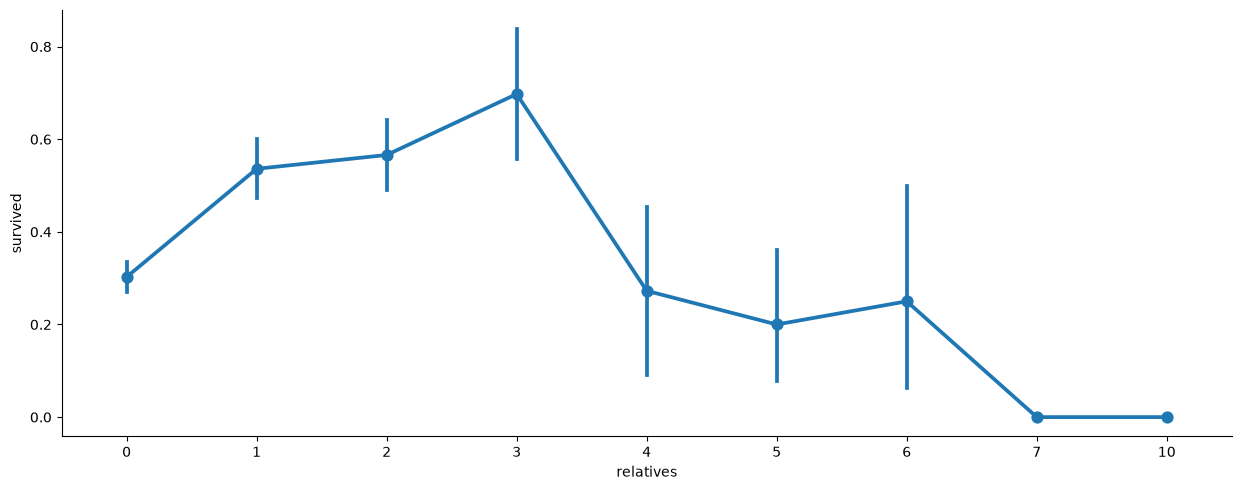

In [7]:
axes = sns.catplot(x='relatives', y='survived', data=df, aspect=2.5, kind='point')

### Nhận xét
- **Số người đi một mình là 790 người**, **số người đi cùng người thân là 519 người** → phần lớn hành khách (khoảng 60%) đi một mình.
- Người **có người thân đi cùng** có tỷ lệ sống sót **50.3%**, cao hơn hẳn người **đi một mình** (chỉ **30.3%**).
- Những người có **1 đến 3 người thân đi cùng có tỷ lệ sống sót cao nhất** (53.6% → 56.6% → 69.8%), cao nhất là nhóm có 3 người thân. Đây thường là các gia đình nhỏ (vợ chồng, cha mẹ với 1–2 con) nên dễ được ưu tiên và hỗ trợ nhau lên xuồng cứu sinh.
- Từ **4 đến 6 người thân**, tỷ lệ sống sót giảm mạnh, chỉ còn khoảng 20–27%.
- Những người có **7 đến 10 người thân đi cùng có tỷ lệ sống thấp nhất: 0%** (không ai sống sót trong 19 người). Các gia đình đông người phần lớn đi vé hạng 3, khó tập hợp và di chuyển cùng nhau.
- Lưu ý: các nhóm từ 4 người thân trở lên có ít hành khách (8–25 người) nên thanh sai số trên biểu đồ dài, kết quả kém ổn định hơn.
- **Kết luận:** số người đi cùng có liên quan đến khả năng sống sót nhưng **không theo quan hệ tuyến tính**: đi một mình hoặc gia đình quá đông đều bất lợi, gia đình nhỏ (1–3 người thân) có lợi nhất. Có thể dùng thuộc tính mới `relatives` hoặc `not_alone` cho các bước khai thác sau.